# 04 — Classifier training and evaluation (benign vs malignant; BI-RADS gated)

**Objectives.**
* **Pathway A:** train interpretable radiomics baselines (logistic regression, random forest,
  gradient boosting) for **benign vs malignant**, the only labels BUSI provides. Compare them with the
  existing ResNet50 on identical cases, with leakage-safe grouping, training-only preprocessing,
  confidence intervals and calibration. Save a reusable artifact for the app.
* **Pathway B:** a BI-RADS category classifier. Its training interface is implemented, but it is
  **blocked** because notebook 01 found no radiologist BI-RADS labels.

**Protocol.**
| step | data |
|---|---|
| hyper-parameter search + model choice | train split, `gt_mask` records, 5-fold StratifiedGroupKFold |
| probability calibration (Platt) | val split, `cascade` records (real-inference masks) |
| final evaluation, run once | test split: `cascade` (real inference), `unet_on_gt_box`, `gt_mask` (oracle) |

**Prerequisites.** Notebooks 01–02. **Outputs.** `results/models/radiomics_classifier/`
(`model.joblib`, `metadata.json`, `evaluation.json`, `reliability_test.png`),
`results/models/model_comparison_test.csv`.

> Research model output — not a clinical diagnosis.

## Setup

In [1]:
import json
import os
import sys
from pathlib import Path

# Resolve the repo root whether the kernel starts in notebooks/ or at the root:
# config.yaml paths (dataset/, checkpoints/, results/) are relative to it.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "config.yaml").exists() and (p / "bus_research").is_dir())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.config import load_config
from utils.seed import get_device, set_seed

config = load_config(str(REPO_ROOT / "config.yaml"))
set_seed(config["seed"], config["deterministic"])
RESEARCH = config["research"]
print(f"Repo root: {REPO_ROOT}")

Repo root: /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection


In [2]:
import bus_research

missing = bus_research.missing_dependencies()
print("Missing research dependencies:", missing or "none")
# If anything is missing, install the pinned optional set (see the comments in that file):
# %pip install -r requirements-research.txt

Missing research dependencies: none


In [3]:
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn

from bus_research.feature_store import load_record, pseudonymize
from bus_research.radiomics_extract import flat_features

SEED = config["seed"]
rad_dir = REPO_ROOT / RESEARCH["radiomics"]["output_dir"]
manifest = json.loads((rad_dir / "manifest.json").read_text())
audit = json.loads((REPO_ROOT / "results/audit/dataset_audit.json").read_text())

rows = []
for e in manifest["records"]:
    rec = load_record(rad_dir / e["record_path"])
    pred = rec["prediction"]["class_probabilities"] or {}
    rows.append({"record_id": e["record_id"], "image_id": e["image_id"], "lesion_id": e["lesion_id"],
                 "group_id": e["group_id"], "split": e["split"], "variant": e["variant"],
                 "label": rec["reference_labels"]["benign_malignant"],
                 "ok": rec["radiomics"]["status"] == "ok", "qc": rec["segmentation"]["quality_status"],
                 "p_resnet": pred.get("malignant"), **flat_features(rec["radiomics"])})
df = pd.DataFrame(rows)
df["y"] = (df.label == "malignant").astype(int)
print(df.groupby(["variant", "split"]).agg(n=("record_id", "size"), ok=("ok", "sum"), malignant=("y", "sum")))

                        n   ok  malignant
variant        split                     
cascade        test    88   88         27
               train  449  449        143
               val     84   84         28
gt_mask        test   100  100         31
               train  461  461        146
               val    104  104         34
unet_on_gt_box test   100  100         31
               train  461  461        146
               val    104  104         34


## 1. Label and leakage audit (before any fitting)

* **Groups.** Images with byte-identical content share a `group_id` (notebook 02). The near-duplicate
  pairs found in notebook 01 are merged into the same cluster with union-find. Cross-validation folds and
  bootstrap resampling operate on these clusters.
* **Cross-split contamination.** The existing split predates the near-duplicate audit, and the trained
  CNN checkpoints depend on it, so it is kept. Test images whose cluster also contains a train image
  are flagged, and results are also reported on the clean subset.

In [4]:
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)

group_of_image = dict(zip(df.image_id, df.group_id))
for g in df.group_id.unique():
    find(g)
for pair in audit["near_duplicate_pairs"]:
    a, b = pseudonymize(pair["image_a"], "img"), pseudonymize(pair["image_b"], "img")
    if a in group_of_image and b in group_of_image:
        union(group_of_image[a], group_of_image[b])
df["cluster"] = df.group_id.map(find)

splits_per_cluster = df[df.variant == "gt_mask"].groupby("cluster").split.agg(lambda s: set(s))
train_clusters = {c for c, s in splits_per_cluster.items() if "train" in s}
df["test_contaminated"] = (df.split != "train") & df.cluster.isin(train_clusters)
print("clusters:", df.cluster.nunique(), "| content groups:", df.group_id.nunique())
print("byte-identical groups spanning splits:", sum(len(s) > 1 for s in df[df.variant == "gt_mask"].groupby("group_id").split.agg(set)))
print("near-duplicate clusters spanning splits:", int((splits_per_cluster.map(len) > 1).sum()))
print("test images with a near-duplicate in train:",
      df[(df.variant == "cascade") & (df.split == "test")].test_contaminated.sum(), "of",
      ((df.variant == "cascade") & (df.split == "test")).sum())

FEATURE_FAMILIES = ("shape2D", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm")
feat_cols = [c for c in df.columns if c.split(".")[0] in FEATURE_FAMILIES]
forbidden = {"label", "y", "split", "record_id", "image_id", "lesion_id", "group_id", "cluster", "p_resnet", "qc",
             "variant", "test_contaminated", "ok"}
assert not forbidden & set(feat_cols), "identifiers/labels must never be predictors"
print("candidate radiomics predictors:", len(feat_cols))

clusters: 538 | content groups: 646
byte-identical groups spanning splits: 0
near-duplicate clusters spanning splits: 45
test images with a near-duplicate in train: 22 of 88
candidate radiomics predictors: 102


## 2. Training data (train split, ground-truth masks)

In [5]:
train = df[(df.variant == "gt_mask") & (df.split == "train") & df.ok].reset_index(drop=True)
present = train[feat_cols].notna().mean()
feature_names = [c for c in feat_cols if present[c] >= 0.99 and train[c].std() > 0]
dropped = sorted(set(feat_cols) - set(feature_names))
X_train, y_train, g_train = train[feature_names].to_numpy(float), train.y.to_numpy(), train.cluster.to_numpy()
print(f"train lesions: {len(train)} (malignant {y_train.sum()}, benign {(1 - y_train).sum()}), "
      f"clusters: {len(set(g_train))}")
print(f"features used: {len(feature_names)} | dropped (missing/constant): {dropped or 'none'}")
print(f"events per feature: {y_train.sum() / len(feature_names):.2f} -> strong regularisation needed")

train lesions: 461 (malignant 146, benign 315), clusters: 395
features used: 102 | dropped (missing/constant): none
events per feature: 1.43 -> strong regularisation needed


## 3. Hyper-parameter search on train only

Imputation, scaling and the estimator are inside one `Pipeline`, so every fold fits them on its own
training part. Class imbalance is handled with `class_weight` (no resampling). There is no feature
selection step outside the pipeline.

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "logistic_regression": (
        Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=10000))]),
        {"scale": [StandardScaler(), QuantileTransformer(output_distribution="normal", n_quantiles=200,
                                                         random_state=SEED)],
         "clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}),
    "random_forest": (
        Pipeline([("impute", SimpleImputer(strategy="median")),
                  ("clf", RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                                 random_state=SEED, n_jobs=1))]),
        {"clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.2]}),
    "gradient_boosting": (
        Pipeline([("impute", SimpleImputer(strategy="median")),
                  ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_iter=300,
                                                         early_stopping=False, random_state=SEED))]),
        {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3], "clf__l2_regularization": [0.0, 1.0]}),
}
searches, cv_rows = {}, []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    for name, (pipe, grid) in candidates.items():
        search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
        search.fit(X_train, y_train, groups=g_train)
        searches[name] = search
        i = search.best_index_
        cv_rows.append({"model": name, "cv_auc_mean": search.cv_results_["mean_test_score"][i],
                        "cv_auc_sd": search.cv_results_["std_test_score"][i],
                        "best_params": {k: str(v) for k, v in search.best_params_.items()}})
cv_table = pd.DataFrame(cv_rows).sort_values("cv_auc_mean", ascending=False)
print(cv_table.to_string(index=False))
SELECTED = cv_table.iloc[0].model
print("\nselected by grouped CV AUC on train (before seeing val/test):", SELECTED)

              model  cv_auc_mean  cv_auc_sd                                                                                                                           best_params
  gradient_boosting     0.990608   0.004583                                                 {'clf__l2_regularization': '0.0', 'clf__learning_rate': '0.1', 'clf__max_depth': '3'}
logistic_regression     0.987040   0.008556 {'clf__C': '1.0', 'scale': 'QuantileTransformer(n_quantiles=200, output_distribution='normal',
                    random_state=42)'}
      random_forest     0.956994   0.017434                                                                            {'clf__max_features': '0.2', 'clf__min_samples_leaf': '1'}

selected by grouped CV AUC on train (before seeing val/test): gradient_boosting


## 4. Calibration on the validation split (real-inference masks)

In [7]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

val = df[(df.variant == "cascade") & (df.split == "val") & df.ok].reset_index(drop=True)
X_val, y_val = val[feature_names].to_numpy(float), val.y.to_numpy()
calibrated = {}
for name, search in searches.items():
    cal = CalibratedClassifierCV(FrozenEstimator(search.best_estimator_), method="sigmoid")
    calibrated[name] = cal.fit(X_val, y_val)

# The ResNet50's own softmax gets the same Platt treatment on the same val images, for a fair comparison.
def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)
resnet_platt = LogisticRegression(C=1e6).fit(logit(val.p_resnet), y_val)
print(f"calibration set: {len(val)} val images ({y_val.sum()} malignant); "
      f"isotonic not used (too few events for a stable step function)")

calibration set: 84 val images (28 malignant); isotonic not used (too few events for a stable step function)


## 5. Final evaluation on the test split (run once)

Metrics at threshold 0.5, with 95% CIs from 2,000 bootstrap resamples of **clusters** (so
near-duplicates move together). ResNet50 probabilities come from the same records, i.e. from the
same masks as the radiomics features.

In [8]:
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             roc_auc_score)

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    return float(sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def point_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"n": len(y), "n_malignant": int(y.sum()), "roc_auc": roc_auc_score(y, p),
            "pr_auc": average_precision_score(y, p), "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else np.nan, "f1": f1_score(y, pred, zero_division=0),
            "brier": brier_score_loss(y, p), "ece": ece(y, p), "tn": int(tn), "fp": int(fp), "fn": int(fn),
            "tp": int(tp)}

def bootstrap_ci(y, p, groups, keys=("roc_auc", "pr_auc", "sensitivity", "specificity"), n=2000):
    rng = np.random.default_rng(SEED)
    uniq = np.unique(groups)
    members = {g: np.flatnonzero(groups == g) for g in uniq}
    stats = {k: [] for k in keys}
    for _ in range(n):
        idx = np.concatenate([members[g] for g in rng.choice(uniq, len(uniq), replace=True)])
        if len(set(y[idx])) < 2:
            continue
        m = point_metrics(y[idx], p[idx])
        for k in keys:
            stats[k].append(m[k])
    return {k: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))] for k, v in stats.items()}

def paired_auc_diff(y, pa, pb, groups, n=2000):
    rng = np.random.default_rng(SEED)
    uniq = np.unique(groups)
    members = {g: np.flatnonzero(groups == g) for g in uniq}
    diffs = []
    for _ in range(n):
        idx = np.concatenate([members[g] for g in rng.choice(uniq, len(uniq), replace=True)])
        if len(set(y[idx])) == 2:
            diffs.append(roc_auc_score(y[idx], pa[idx]) - roc_auc_score(y[idx], pb[idx]))
    return float(roc_auc_score(y, pa) - roc_auc_score(y, pb)), [float(np.percentile(diffs, 2.5)),
                                                                 float(np.percentile(diffs, 97.5))]

def scores_for(subset):
    X = subset[feature_names].to_numpy(float)
    out = {f"radiomics_{n} (Platt)": calibrated[n].predict_proba(X)[:, 1] for n in calibrated}
    out["resnet50 (raw softmax)"] = subset.p_resnet.to_numpy(float)
    out["resnet50 (Platt)"] = resnet_platt.predict_proba(logit(subset.p_resnet))[:, 1]
    return out

settings_eval = {
    "real_inference (cascade)": df[(df.variant == "cascade") & (df.split == "test") & df.ok],
    "segmentation_only (unet_on_gt_box)": df[(df.variant == "unet_on_gt_box") & (df.split == "test") & df.ok],
    "oracle (gt_mask)": df[(df.variant == "gt_mask") & (df.split == "test") & df.ok],
    "real_inference, deduplicated test": df[(df.variant == "cascade") & (df.split == "test") & df.ok
                                            & ~df.test_contaminated],
}
results, table = {}, []
for setting, subset in settings_eval.items():
    subset = subset.reset_index(drop=True)
    y, groups = subset.y.to_numpy(), subset.cluster.to_numpy()
    results[setting] = {}
    for model, p in scores_for(subset).items():
        m = point_metrics(y, p)
        m["ci95"] = bootstrap_ci(y, p, groups)
        results[setting][model] = m
        table.append({"setting": setting, "model": model, "n": m["n"], "malignant": m["n_malignant"],
                      "AUC": f"{m['roc_auc']:.3f} [{m['ci95']['roc_auc'][0]:.3f}-{m['ci95']['roc_auc'][1]:.3f}]",
                      "PR-AUC": f"{m['pr_auc']:.3f}", "sens": f"{m['sensitivity']:.2f}",
                      "spec": f"{m['specificity']:.2f}", "F1": f"{m['f1']:.2f}", "Brier": f"{m['brier']:.3f}",
                      "ECE": f"{m['ece']:.3f}"})
comparison = pd.DataFrame(table)
pd.set_option("display.width", 250)
print(comparison.to_string(index=False))
n_det_fail = sum(1 for d in manifest["detection_failures"] if d["split"] == "test")
print(f"\nreal-inference test excludes {n_det_fail} image(s) with no YOLO detection (as evaluation/cascade.py does)")

                           setting                                 model   n  malignant                 AUC PR-AUC sens spec   F1 Brier   ECE
          real_inference (cascade) radiomics_logistic_regression (Platt)  88         27 0.869 [0.788-0.941]  0.678 0.56 0.89 0.61 0.144 0.112
          real_inference (cascade)       radiomics_random_forest (Platt)  88         27 0.915 [0.845-0.968]  0.845 0.85 0.85 0.78 0.121 0.131
          real_inference (cascade)   radiomics_gradient_boosting (Platt)  88         27 0.894 [0.822-0.956]  0.725 0.74 0.87 0.73 0.128 0.083
          real_inference (cascade)                resnet50 (raw softmax)  88         27 0.892 [0.821-0.952]  0.752 0.81 0.84 0.75 0.147 0.151
          real_inference (cascade)                      resnet50 (Platt)  88         27 0.892 [0.821-0.952]  0.752 0.78 0.87 0.75 0.121 0.070
segmentation_only (unet_on_gt_box) radiomics_logistic_regression (Platt) 100         31 0.913 [0.853-0.961]  0.751 0.48 0.93 0.59 0.129 0.134
segmen

In [9]:
real = settings_eval["real_inference (cascade)"].reset_index(drop=True)
sel_key = f"radiomics_{SELECTED} (Platt)"
p_rad = scores_for(real)[sel_key]
diff, ci = paired_auc_diff(real.y.to_numpy(), p_rad, real.p_resnet.to_numpy(float), real.cluster.to_numpy())
print(f"paired AUC difference, {sel_key} - ResNet50, real inference: {diff:+.3f} (95% CI {ci[0]:+.3f} to {ci[1]:+.3f})")

# Downstream effect of segmentation error on the radiomics prediction, lesion by lesion.
seg = settings_eval["segmentation_only (unet_on_gt_box)"].set_index("lesion_id")
ora = settings_eval["oracle (gt_mask)"].set_index("lesion_id")
both = seg.index.intersection(ora.index)
p_seg = calibrated[SELECTED].predict_proba(seg.loc[both, feature_names].to_numpy(float))[:, 1]
p_ora = calibrated[SELECTED].predict_proba(ora.loc[both, feature_names].to_numpy(float))[:, 1]
flips = int(((p_seg >= 0.5) != (p_ora >= 0.5)).sum())
print(f"U-Net vs ground-truth mask, same {len(both)} test lesions: median |dp| = {np.median(np.abs(p_seg - p_ora)):.3f}, "
      f"max |dp| = {np.abs(p_seg - p_ora).max():.3f}, decision flips at 0.5: {flips}")

paired AUC difference, radiomics_gradient_boosting (Platt) - ResNet50, real inference: +0.002 (95% CI -0.057 to +0.060)
U-Net vs ground-truth mask, same 100 test lesions: median |dp| = 0.039, max |dp| = 0.588, decision flips at 0.5: 13


### How to read these results

* **Only the real-inference rows describe the deployed system.** The radiomics model and ResNet50 see
  the same YOLO + U-Net masks there. The paired bootstrap above is the head-to-head test; a CI that
  spans 0 means **no evidence that either model is better**.
* **The oracle rows are not achievable at inference time.** They are also suspiciously high: the
  selected model leans almost entirely on mask *shape* (Sphericity, Elongation, section 6). With
  ground-truth masks, shape nearly separates the classes, which is consistent with BUSI annotators
  tracing malignant outlines more irregularly (annotation style) and not only with tumour biology. The
  drop from oracle to segmentation-only to real inference is the price of replacing hand-drawn
  outlines with U-Net output. The decision-flip count above quantifies it lesion by lesion.
* **Model selection was fixed by grouped CV on train before the test set was scored.** Another
  radiomics model scoring higher on test is not a reason to switch: that would be selection on the
  test set.
* **Pre-specified follow-up (not run here):** train on `unet_on_gt_box` features (predicted masks) to
  reduce the train/inference mask shift. Choose between that and the current model on **val** only,
  then re-score test once.

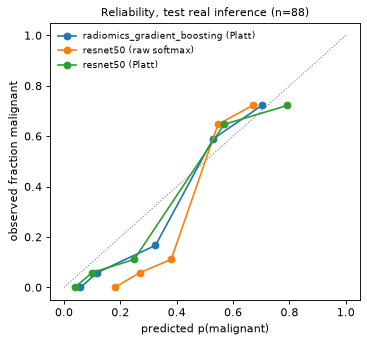

In [10]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

art_dir = REPO_ROOT / RESEARCH["models"]["classifier_dir"]
art_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=80)
ax.plot([0, 1], [0, 1], ls=":", c="gray", lw=1)
for label, p in ((sel_key, p_rad), ("resnet50 (raw softmax)", real.p_resnet.to_numpy(float)),
                 ("resnet50 (Platt)", scores_for(real)["resnet50 (Platt)"])):
    frac, mean_pred = calibration_curve(real.y, p, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", lw=1.5, label=label)
ax.set_xlabel("predicted p(malignant)"); ax.set_ylabel("observed fraction malignant")
ax.set_title(f"Reliability, test real inference (n={len(real)})", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.savefig(art_dir / "reliability_test.png", bbox_inches="tight")
plt.show()

**Reading the reliability plot.** With about 95 test images and 5 quantile bins, each point rests on
about 19 cases, so these curves are coarse. "Calibrated" here means calibrated to **BUSI validation
prevalence**. It does not mean calibrated to the clinical likelihood of malignancy in any screening or
diagnostic population.

## 6. What drives the selected model (validation set, permutation importance)

In [11]:
from sklearn.inspection import permutation_importance

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    imp = permutation_importance(searches[SELECTED].best_estimator_, X_val, y_val, scoring="roc_auc",
                                 n_repeats=20, random_state=SEED)
importance = (pd.DataFrame({"feature": feature_names, "auc_drop_mean": imp.importances_mean,
                            "auc_drop_sd": imp.importances_std})
              .sort_values("auc_drop_mean", ascending=False))
print(importance.head(12).round(4).to_string(index=False))

                                  feature  auc_drop_mean  auc_drop_sd
                       shape2D.Sphericity         0.1905       0.0630
                       shape2D.Elongation         0.0802       0.0259
                           ngtdm.Strength         0.0057       0.0103
                      firstorder.Skewness         0.0026       0.0008
                        firstorder.Median         0.0019       0.0013
                  glrlm.GrayLevelVariance         0.0019       0.0015
                         glrlm.RunEntropy         0.0018       0.0007
gldm.LargeDependenceHighGrayLevelEmphasis         0.0014       0.0011
                    glrlm.LongRunEmphasis         0.0011       0.0009
                           ngtdm.Contrast         0.0008       0.0007
   glrlm.RunLengthNonUniformityNormalized         0.0008       0.0016
            glrlm.LowGrayLevelRunEmphasis         0.0007       0.0008


## 7. Image + radiomics fusion — not trained (justification)

A fusion model (radiomics features + ResNet50 probability) would need ResNet50 outputs on the
**training** lesions that were not seen during CNN training. The available ResNet50 was trained on
this train split, so its train-set probabilities are in-sample and close to 0/1. A fusion model fitted on
them would learn to trust the CNN almost completely, and its test performance would be misleading.
A valid fusion would need out-of-fold CNN predictions (k CNNs retrained), which is outside this
notebook's no-expensive-training constraint. It is therefore **not implemented**.

## 8. Save the reusable artifact

In [12]:
import hashlib

import joblib

from bus_research.classifier import CLASS_ORDER, PREDICTION_TYPE, RadiomicsClassifier
from bus_research.feature_store import atomic_write_json
from bus_research.radiomics_extract import EXTRACTION_VERSION, pyradiomics_version

final_model = calibrated[SELECTED]
assert list(final_model.classes_) == [0, 1]
best_params = {k: str(v) for k, v in searches[SELECTED].best_params_.items()}
model_id = "radiomics-{}-{}".format(SELECTED.replace("_", "-"), hashlib.sha256(json.dumps(
    [feature_names, best_params, manifest["settings_hash"], len(train)]).encode()).hexdigest()[:8])
joblib.dump(final_model, art_dir / "model.joblib")
headline = results["real_inference (cascade)"][sel_key]
metadata = {
    "model_id": model_id,
    "prediction_type": PREDICTION_TYPE,
    "class_order": CLASS_ORDER,
    "positive_class": "malignant",
    "estimator": SELECTED,
    "best_params": best_params,
    "feature_names": feature_names,
    "required_settings_hash": manifest["settings_hash"],
    "required_extraction_version": EXTRACTION_VERSION,
    "calibration": {
        "status": "calibrated", "method": "sigmoid (Platt) on frozen estimator",
        "fitted_on": f"val split, cascade records (real-inference masks), n={len(val)}",
        "scope": "Calibrated to BUSI validation prevalence only. NOT calibrated to clinical likelihood of "
                 "malignancy; must not be mapped to BI-RADS 3/4A/4B/4C/5 likelihood bands.",
    },
    "train_feature_stats": {"mean": np.nanmean(X_train, 0).tolist(), "std": np.nanstd(X_train, 0).tolist(),
                            "z_limit": 6.0, "max_extreme_fraction": 0.1},
    "training": {
        "records": "gt_mask variant, train split", "n_lesions": int(len(train)),
        "class_counts": {"benign": int((y_train == 0).sum()), "malignant": int(y_train.sum())},
        "label_source": "BUSI class folder (benign/malignant)", "grouping": "content groups + near-duplicate clusters",
        "cv": "StratifiedGroupKFold(5, shuffle, seed)", "cv_results": cv_rows, "seed": SEED,
        "radiomics_manifest_sha256": hashlib.sha256((rad_dir / "manifest.json").read_bytes()).hexdigest()[:16],
    },
    "versions": {"sklearn": sklearn.__version__, "pyradiomics": pyradiomics_version(), "numpy": np.__version__},
    "evaluation_summary": {"setting": "test, real inference (YOLO+U-Net masks)",
                           **{k: headline[k] for k in ("n", "roc_auc", "pr_auc", "sensitivity", "specificity",
                                                       "brier", "ece")},
                           "roc_auc_ci95": headline["ci95"]["roc_auc"]},
    "not_a_birads_model": True,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
atomic_write_json(art_dir / "metadata.json", metadata)
atomic_write_json(art_dir / "evaluation.json", {"selected": SELECTED, "cv": cv_rows, "results": results,
                                                "paired_auc_diff_vs_resnet_real": {"diff": diff, "ci95": ci},
                                                "segmentation_effect": {"n": int(len(both)), "flips": flips,
                                                    "median_abs_dp": float(np.median(np.abs(p_seg - p_ora)))},
                                                "permutation_importance_val": importance.head(20).to_dict("records")})
comparison.to_csv(REPO_ROOT / RESEARCH["models"]["output_dir"] / "model_comparison_test.csv", index=False)

# Round-trip: the runtime loader must reproduce the notebook's predictions exactly.
loaded = RadiomicsClassifier.load(art_dir)
rec = load_record(rad_dir / manifest["records"][[e["record_id"] for e in manifest["records"]].index(real.record_id[0])]["record_path"])
p_runtime = loaded.predict(rec)["class_probabilities"]["malignant"]
assert abs(p_runtime - p_rad[0]) < 1e-12, (p_runtime, p_rad[0])
print("saved", model_id, "->", art_dir.relative_to(REPO_ROOT), "| runtime reproduces notebook prediction:", p_runtime)

saved radiomics-gradient-boosting-c622ae6f -> results/models/radiomics_classifier | runtime reproduces notebook prediction: 0.3961213027754464


## 9. Pathway B — BI-RADS category classifier (interface implemented, training blocked)

`train_birads_classifier` is the configurable entry point. It refuses to run unless
`birads_training_gate` accepts the labels: lesion-level radiologist assessments, valid categories, no
0/6 in the risk-scale target, and enough lesions per class. When it does run, it trains a multinomial
model on radiomics with grouped CV and reports per-class metrics, macro averages, the confusion matrix
and **ordinal** error (mean absolute category distance on 1-2-3-4A-4B-4C-5).

In [13]:
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict

from bus_research.birads import ORDINAL_RISK_ORDER, birads_training_gate, normalize_category

def train_birads_classifier(X, labels, label_source, groups, min_per_class=20):
    gate = birads_training_gate(labels, label_source, min_per_class=min_per_class)
    if not gate.allowed:
        raise RuntimeError("BI-RADS training blocked: " + " ".join(gate.reasons))
    y = np.array([normalize_category(v) for v in labels])
    model = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                      ("clf", LogisticRegression(class_weight="balanced", max_iter=10000, C=0.1))])
    pred = cross_val_predict(model, X, y, groups=groups, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED))
    order = [c for c in ORDINAL_RISK_ORDER if c in set(y)]
    rank = {c: i for i, c in enumerate(ORDINAL_RISK_ORDER)}
    report = {
        "per_class": classification_report(y, pred, labels=order, output_dict=True, zero_division=0),
        "confusion_matrix": {"labels": order, "matrix": confusion_matrix(y, pred, labels=order).tolist()},
        "mean_ordinal_error": float(np.mean([abs(rank[a] - rank[b]) for a, b in zip(y, pred)])),
    }
    return model.fit(X, y), report

# BUSI: no BI-RADS labels exist (notebook 01) -> blocked, by design.
try:
    train_birads_classifier(X_train, labels=None, label_source=None, groups=g_train)
except RuntimeError as exc:
    print(exc)
# Deriving labels from the benign/malignant folders is refused too:
try:
    fake = np.where(y_train == 1, "5", "2").tolist()
    train_birads_classifier(X_train, labels=fake, label_source="derived_from_benign_malignant", groups=g_train)
except RuntimeError as exc:
    print(exc)

BI-RADS training blocked: No BI-RADS reference labels are present in the dataset.
BI-RADS training blocked: Label source is 'derived_from_benign_malignant'; only lesion-level radiologist assessments are accepted (not pathology, benign/malignant folders, model probabilities, or generated text). Only 2 category(ies) have >= 20 lesions; need 3.


### Why calibrated probabilities are **not** mapped to BI-RADS 4A/4B/4C/5

The commonly cited likelihood bands (4A >2–10%, 4B >10–50%, 4C >50–<95%, 5 ≥95%) describe a
radiologist's assessment in clinical populations. This model's probabilities are calibrated to a
benign/malignant research dataset with ~33% prevalence. That is not the population or the quantity
the bands refer to. Categories 0, 1, 2, 3 and 6 also are not functions of a malignancy score at all.
Mapping p = 0.30 to "4B" would therefore manufacture a clinical label, so the app and reports show
**"BI-RADS assessment unavailable: validated BI-RADS labels/model not configured."**

## Limitations

* About 450 training lesions for about 100 features; the radiomics models are heavily regularised.
  The test set is small (about 30 malignant), so confidence intervals are wide.
* The split is image-level. Patient-level independence cannot be verified, and the near-duplicate
  audit shows cross-split leakage. Compare the "deduplicated test" rows with the full-test rows.
* Labels are BUSI folder labels and include cross-label near-identical frames (notebook 01). These
  have not been re-verified.
* The ResNet50 baseline uses the checkpoint as trained in Stage 4. Its validation split was used for its
  own early stopping, so its Platt-calibrated variant reuses that val split.